In [4]:
%pip install numpy scipy matplotlib h5py gwosc


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
%pip install truststore

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
import truststore
truststore.inject_into_ssl()   # use Windows' trusted certificates

import os
import numpy as np
import matplotlib.pyplot as plt
import h5py
import urllib.request
from scipy.signal import welch, sosfiltfilt, butter, iirnotch, tf2sos
from scipy.signal.windows import tukey
from scipy.signal import freqz, sosfreqz
from gwosc.locate import get_event_urls
from gwosc.datasets import event_gps

A: Settings:

In [11]:
EVENT = 'GW150914'
DETECTOR = 'H1'
DURATION = 32                  # seconds of data
F_HP = 15                      # high-pass cut (Hz), well below the signal (~35 Hz)
F_LOW, F_HIGH = 35, 350        # band-pass edges (Hz)
NOTCH_FREQS = (60, 120, 180)   # US mains line and harmonics
PSD_SEG = 4                    # seconds per Welch segment
os.makedirs('figures', exist_ok=True)

In [14]:
print('Notebook folder:', os.getcwd())
for name in os.listdir('.'):
    if name.endswith(('.hdf5', '.part')):
        print(name, round(os.path.getsize(name) / 1e6, 1), 'MB')

Notebook folder: c:\Users\stels\OneDrive\Desktop
H1_GW150914.hdf5 120.3 MB


B: Loading:

In [18]:
def show_progress(blocks, block_size, total):
    """Print download progress on one line (urllib calls this as data arrives)."""
    done = blocks * block_size
    if total > 0:
        print(f'\r{min(done / total, 1) * 100:5.1f}%  of {total / 1e6:.0f} MB', end='')
    else:                                            # server didn't say how big the file is
        print(f'\r{done / 1e6:.1f} MB downloaded', end='')

def load_strain(event, detector, duration):
    """Download the GWOSC bulk file once, cut out `duration` seconds centred on the event,
    and cache that short segment. Returns strain, fs, times relative to event."""
    cache = f'{detector}_{event}_{duration}s.npz'
    if not os.path.exists(cache):
        big = f'{detector}_{event}_bulk.hdf5'
        if not os.path.exists(big):
            url = get_event_urls(event, detector=detector, sample_rate=4096, duration=4096)[0]
            print('Downloading', url, '(about 130 MB, only once)')
            urllib.request.urlretrieve(url, big + '.part', reporthook=show_progress)
            os.replace(big + '.part', big)          # only becomes "the file" once complete
            print('\nDownload complete')
        t0 = event_gps(event)
        with h5py.File(big, 'r') as f:
            dset = f['strain/Strain']
            dt = dset.attrs['Xspacing']
            t_start = f['meta/GPSstart'][()]
            i_event = int(round((t0 - t_start) / dt))   # sample index of the event
            half = int(round(duration / 2 / dt))
            strain = dset[i_event - half : i_event + half]   # reads only these samples
            seg_start = t_start + (i_event - half) * dt
        np.savez(cache, strain=strain, dt=dt, seg_start=seg_start, t0=t0)
    c = np.load(cache)
    strain, dt = c['strain'], float(c['dt'])
    times = c['seg_start'] + np.arange(len(strain)) * dt - float(c['t0'])
    return strain, 1.0 / dt, times

strain, fs, times = load_strain(EVENT, DETECTOR, DURATION)
print(len(strain), 'samples at', fs, 'Hz =', len(strain) / fs, 's')   # expect 131072 ... 32.0 s
print('Any missing values?', np.isnan(strain).any())                  # expect False

100.0%  of 130 MB
Download complete
131072 samples at 4096.0 Hz = 32.0 s
Any missing values? False


C: Whitening (normalised): 

In [19]:
def highpass(data, fs, f_cut=F_HP):
    """Remove the huge low-frequency noise so it can't leak into the PSD estimate."""
    sos = butter(8, f_cut, btype='highpass', fs=fs, output='sos')
    return sosfiltfilt(sos, data)

def whiten(data, fs, psd_seg=PSD_SEG):
    """Divide out the noise spectrum so the noise has unit variance."""
    freqs_psd, psd = welch(data, fs=fs, nperseg=int(psd_seg * fs))
    freqs = np.fft.rfftfreq(len(data), 1 / fs)
    psd_interp = np.interp(freqs, freqs_psd, psd)
    window = tukey(len(data), alpha=0.1)
    white_f = np.fft.rfft(data * window) / np.sqrt(psd_interp * fs / 2)
    return np.fft.irfft(white_f, n=len(data))

def bandpass_notch(data, fs, f_low=F_LOW, f_high=F_HIGH, notches=NOTCH_FREQS):
    """Zero-phase band-pass, then notch out mains lines."""
    sos = butter(4, [f_low, f_high], btype='bandpass', fs=fs, output='sos')
    out = sosfiltfilt(sos, data)
    for f0 in notches:
        b, a = iirnotch(f0, Q=30, fs=fs)
        out = sosfiltfilt(tf2sos(b, a), out)
    return out

white = whiten(highpass(strain, fs), fs)    # high-pass FIRST, then whiten
clean = bandpass_notch(white, fs)

D: Noise check:

In [20]:
quiet = (times > -12) & (times < -4)   # away from the event and the tapered edges

# Reference: same processing on pure white noise, where the right answer is known
ref = bandpass_notch(whiten(np.random.default_rng(0).normal(size=len(strain)), fs), fs)
expected = np.std(ref[quiet])

no_hp = bandpass_notch(whiten(strain, fs), fs)
print('In-band std WITHOUT high-pass:', np.std(no_hp[quiet]))
print('Std of whitened noise:        ', np.std(white[quiet]))   # should be close to 1
print('In-band std WITH high-pass:   ', np.std(clean[quiet]), ' expected:', expected)

In-band std WITHOUT high-pass: 0.3479666263201184
Std of whitened noise:         0.9808592366007842
In-band std WITH high-pass:    0.34796688775421686  expected: 0.3499056003513904


E: Plotting

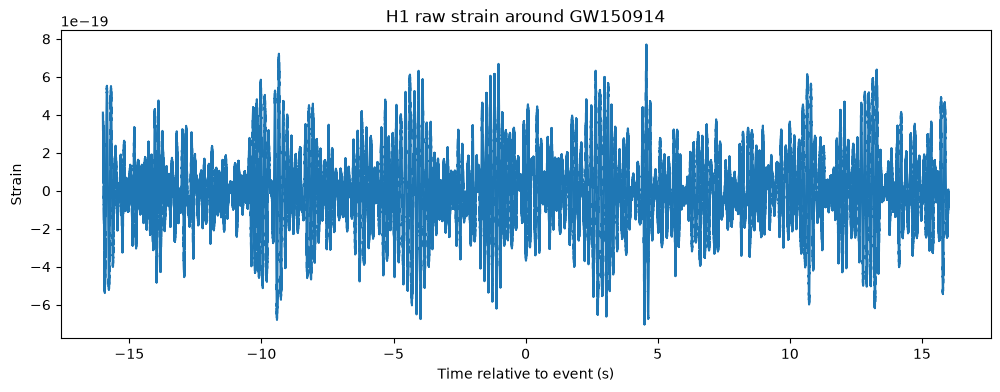

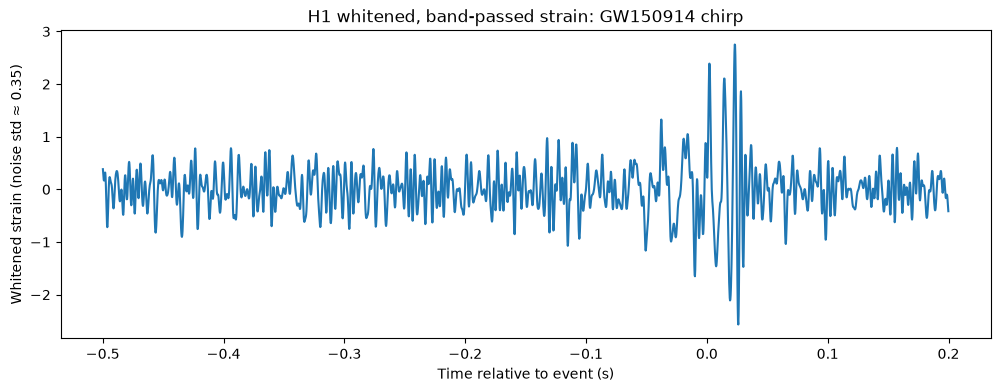

In [21]:
plt.figure(figsize=(12, 4))
plt.plot(times, strain)
plt.xlabel('Time relative to event (s)')
plt.ylabel('Strain')
plt.title('H1 raw strain around GW150914')
plt.savefig('figures/raw_strain.png', dpi=150)
plt.show()

m = (times > -0.5) & (times < 0.2)
plt.figure(figsize=(12, 4))
plt.plot(times[m], clean[m])
plt.xlabel('Time relative to event (s)')
plt.ylabel('Whitened strain (noise std ≈ 0.35)')
plt.title('H1 whitened, band-passed strain: GW150914 chirp')
plt.savefig('figures/whitened_chirp.png', dpi=150)
plt.show()

At leading (Newtonian) order, the inspiral depends on only one mass combination, the chirp mass. With τ = t_c − t (time left until coalescence) and T = G·Mc/c³ (the chirp mass expressed in seconds):

Frequency: f(τ) = (1/π) · (5 / 256τ)^(3/8) · T^(−5/8). It rises as coalescence approaches, and heavier systems chirp faster.

Phase: Φ(τ) = −2 · (τ / 5T)^(5/8), the time integral of 2πf.

Amplitude: ∝ f^(2/3), so the signal grows as it speeds up.

F: Whitening with data's noise spectrum:

In [22]:
MSUN_S = 4.925491e-6   # G * Msun / c^3, in seconds
F_MAX = 150            # template cut-off (Hz): Newtonian formula fails near merger

def estimate_psd(data, fs, psd_seg=PSD_SEG):
    """Welch PSD, interpolated onto the FFT frequencies of the full data."""
    freqs_psd, psd = welch(data, fs=fs, nperseg=int(psd_seg * fs))
    freqs = np.fft.rfftfreq(len(data), 1 / fs)
    return np.interp(freqs, freqs_psd, psd)

def whiten_with_psd(data, fs, psd):
    """Divide out a GIVEN noise spectrum (the data's), so templates match the data."""
    window = tukey(len(data), alpha=0.1)
    white_f = np.fft.rfft(data * window) / np.sqrt(psd * fs / 2)
    return np.fft.irfft(white_f, n=len(data))

psd = estimate_psd(highpass(strain, fs), fs)    # the data's noise spectrum, estimated once

G: Chirp template:

In [23]:
def chirp_template(t, mc, tc, f_min=F_LOW, f_max=F_MAX):
    """Newtonian inspiral chirp. Returns the cosine and sine versions,
    zero outside f_min..f_max. mc in solar masses, tc in seconds."""
    T = mc * MSUN_S
    tau = tc - t                                   # time left before coalescence
    h_cos, h_sin = np.zeros_like(t), np.zeros_like(t)
    f = np.zeros_like(t)
    ok = tau > 0
    f[ok] = (1 / np.pi) * (5 / (256 * tau[ok]))**(3 / 8) * T**(-5 / 8)
    band = ok & (f >= f_min) & (f <= f_max)
    phase = -2 * (tau[band] / (5 * T))**(5 / 8)
    amp = (f[band] / 100)**(2 / 3)                 # overall scale is arbitrary; fitted later
    h_cos[band] = amp * np.cos(phase)
    h_sin[band] = amp * np.sin(phase)
    return h_cos, h_sin

hc, _ = chirp_template(times, 30, 0.0)
print('Time in band for Mc = 30:', np.count_nonzero(hc) / fs, 's')   # expect ~0.17 s

Time in band for Mc = 30: 0.166748046875 s


H: 30 M0 (Solar masses) testing:

In [24]:
import time

def process(h):
    """Apply the data's whitening and filtering to a template."""
    return bandpass_notch(whiten_with_psd(h, fs, psd), fs)

t = time.time()
p = process(hc)
print('1. one process call:', round(time.time() - t, 3), 's')

def best_fit(mc, tc, win):
    """Fit amplitude and phase by least squares; return model and residual sum of squares."""
    h_cos, h_sin = chirp_template(times, mc, tc)
    A = np.column_stack([process(h_cos)[win], process(h_sin)[win]])
    coef, *_ = np.linalg.lstsq(A, clean[win], rcond=None)
    model = A @ coef
    return model, np.sum((clean[win] - model)**2)

win = (times > -0.3) & (times < 0.05)
t = time.time()
best_fit(30, 0.0, win)
print('2. one best_fit call:', round(time.time() - t, 3), 's')

1. one process call: 0.037 s
2. one best_fit call: 0.067 s


Best tc for Mc = 30: 0.03 s


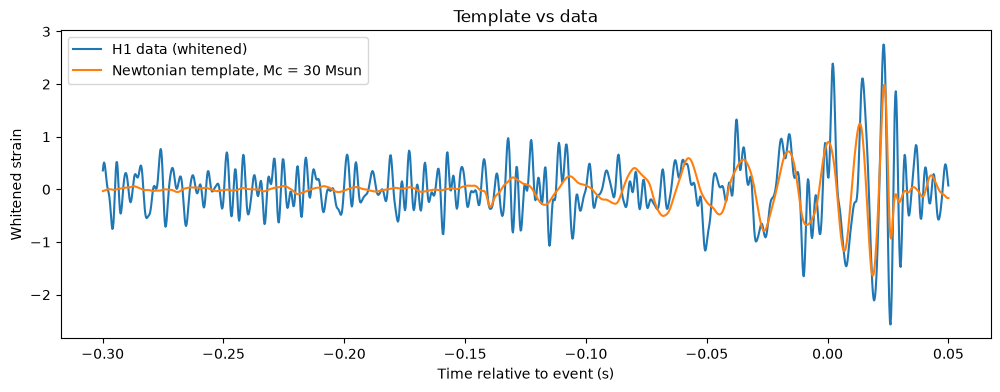

In [25]:
# Combined filter, computed once
freqs = np.fft.rfftfreq(len(times), 1 / fs)
window = tukey(len(times), alpha=0.1)

sos_bp = butter(4, [F_LOW, F_HIGH], btype='bandpass', fs=fs, output='sos')
_, H_bp = sosfreqz(sos_bp, worN=freqs, fs=fs)
gain = np.abs(H_bp)**2                     # filtfilt = forward + backward = |H|^2, zero phase
for f0 in NOTCH_FREQS:
    b, a = iirnotch(f0, Q=30, fs=fs)
    _, H_n = freqz(b, a, worN=freqs, fs=fs)
    gain *= np.abs(H_n)**2

template_filter = gain / np.sqrt(psd * fs / 2) # whitening and filtering in one array

def process(h):
    """Apply the data's whitening and filtering to a template, in one FFT step."""
    return np.fft.irfft(np.fft.rfft(h * window) * template_filter, n=len(h))

# Fit amplitude and phase, scan coalescence time
def best_fit(mc, tc, win):
    """Fit amplitude and phase by least squares; return model and residual sum of squares."""
    h_cos, h_sin = chirp_template(times, mc, tc)
    A = np.column_stack([process(h_cos)[win], process(h_sin)[win]])
    coef, *_ = np.linalg.lstsq(A, clean[win], rcond=None)
    model = A @ coef
    return model, np.sum((clean[win] - model)**2)

win = (times > -0.3) & (times < 0.05)
tcs = np.arange(-0.05, 0.05, 0.002)
rss = [best_fit(30, tc, win)[1] for tc in tcs]
tc_best = tcs[np.argmin(rss)]
print('Best tc for Mc = 30:', round(tc_best, 3), 's')

model, _ = best_fit(30, tc_best, win)
plt.figure(figsize=(12, 4))
plt.plot(times[win], clean[win], label='H1 data (whitened)')
plt.plot(times[win], model, label='Newtonian template, Mc = 30 Msun')
plt.xlabel('Time relative to event (s)')
plt.ylabel('Whitened strain')
plt.title('Template vs data')
plt.legend()
plt.savefig('figures/template_vs_data.png', dpi=150)
plt.show()

I: Likelihood

In [26]:
import time
from scipy.optimize import minimize_scalar

strain_hp = highpass(strain, fs)                    # the same high-passed data the PSD came from
band = (freqs >= F_LOW) & (freqs <= F_MAX)          # only frequencies the template models
n_bins = np.count_nonzero(band)

# Scale so pure noise has unit variance in each real and imaginary part.
# mean(window**2) corrects for the noise power the Tukey taper removes at the edges.
norm = np.sqrt(psd[band] * fs / 2) * np.sqrt(len(times) * np.mean(window**2) / 2)

def whitened_fft(x):
    """FFT restricted to the band, scaled to unit noise variance per real/imag part."""
    return np.fft.rfft(x * window)[band] / norm

d = whitened_fft(strain_hp)
y = np.concatenate([d.real, d.imag])                # data as one real vector

def log_likelihood(mc, tc):
    """Gaussian log-likelihood for (Mc, tc), maximised analytically over amplitude and phase."""
    h_cos, h_sin = chirp_template(times, mc, tc)
    c, s = whitened_fft(h_cos), whitened_fft(h_sin)
    A = np.column_stack([np.concatenate([c.real, c.imag]),
                         np.concatenate([s.real, s.imag])])
    coef, *_ = np.linalg.lstsq(A, y, rcond=None)
    r = y - A @ coef
    return -0.5 * r @ r

J: Normalisation check:

In [27]:
t = time.time()
L_best = log_likelihood(30, tc_best)
print('One likelihood call:', round(time.time() - t, 3), 's')

L_noise = -0.5 * y @ y                              # "no signal at all" model
print('Normalisation check (should be ~1):', round((y @ y) / (2 * n_bins), 3))
print('SNR of the Mc = 30 fit:', round(np.sqrt(2 * (L_best - L_noise)), 1))

One likelihood call: 0.019 s
Normalisation check (should be ~1): 0.957
SNR of the Mc = 30 fit: 12.4


K: Likelihood vs chirp mass

Peak at Mc = 35.0 Msun


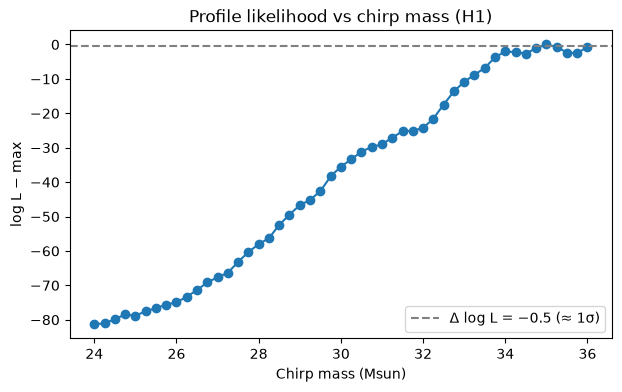

In [28]:
mcs = np.arange(24, 36.01, 0.25)
profile = []
for mc in mcs:
    # for each Mc, find the best tc near the earlier estimate
    res = minimize_scalar(lambda tc: -log_likelihood(mc, tc),
                          bounds=(tc_best - 0.01, tc_best + 0.01),
                          method='bounded', options={'xatol': 1e-6})
    profile.append(-res.fun)
profile = np.array(profile)

print('Peak at Mc =', mcs[np.argmax(profile)], 'Msun')
plt.figure(figsize=(7, 4))
plt.plot(mcs, profile - profile.max(), 'o-')
plt.axhline(-0.5, ls='--', color='grey', label='Δ log L = −0.5 (≈ 1σ)')
plt.xlabel('Chirp mass (Msun)')
plt.ylabel('log L − max')
plt.title('Profile likelihood vs chirp mass (H1)')
plt.legend()
plt.savefig('figures/profile_likelihood.png', dpi=150)
plt.show()

L: Wider profile:

Peak at Mc = 37.0 Msun, tc = 0.0251 s


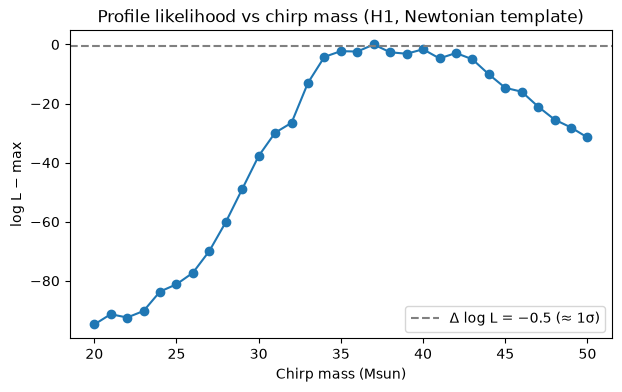

In [29]:
def profile_at(mc):
    """Best log-likelihood over tc for this Mc: coarse grid first, then refine."""
    tcs = np.arange(tc_best - 0.02, tc_best + 0.02, 0.0005)
    vals = [log_likelihood(mc, t) for t in tcs]
    t0 = tcs[np.argmax(vals)]
    res = minimize_scalar(lambda t: -log_likelihood(mc, t),
                          bounds=(t0 - 0.0005, t0 + 0.0005),
                          method='bounded', options={'xatol': 1e-7})
    return -res.fun, res.x

mcs = np.arange(20, 50.1, 1.0)
results = [profile_at(mc) for mc in mcs]
profile = np.array([r[0] for r in results])
tc_at = np.array([r[1] for r in results])

i = np.argmax(profile)
print('Peak at Mc =', mcs[i], 'Msun, tc =', round(tc_at[i], 4), 's')

plt.figure(figsize=(7, 4))
plt.plot(mcs, profile - profile.max(), 'o-')
plt.axhline(-0.5, ls='--', color='grey', label='Δ log L = −0.5 (≈ 1σ)')
plt.xlabel('Chirp mass (Msun)')
plt.ylabel('log L − max')
plt.title('Profile likelihood vs chirp mass (H1, Newtonian template)')
plt.legend()
plt.savefig('figures/profile_likelihood.png', dpi=150)
plt.show()

M: Prior and Posterior:

In [30]:
MC_MIN, MC_MAX = 20, 50                         # flat prior on Mc (Msun)
tc_peak = tc_at[np.argmax(profile)]             # from Cell L
TC_MIN, TC_MAX = tc_peak - 0.02, tc_peak + 0.02 # flat prior on tc (s)

def log_prior(theta):
    """Flat in Mc and tc. Sampling ln Mc, so the density gains a Jacobian factor Mc."""
    ln_mc, tc = theta
    mc = np.exp(ln_mc)
    if not (MC_MIN < mc < MC_MAX and TC_MIN < tc < TC_MAX):
        return -np.inf
    return ln_mc                                 # log of the Jacobian, d(Mc)/d(ln Mc) = Mc

def log_posterior(theta):
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(np.exp(theta[0]), theta[1])

N: Sampler, tuning and convergence 

In [31]:
def metropolis(log_post, start, cov, n_steps, rng):
    """Random-walk Metropolis with a Gaussian proposal of covariance `cov`."""
    d = len(start)
    chain, logp = np.empty((n_steps, d)), np.empty(n_steps)
    x = np.array(start, float)
    lp = log_post(x)
    L = np.linalg.cholesky(cov)                  # so that L @ z has covariance `cov`
    accepted = 0
    for i in range(n_steps):
        proposal = x + L @ rng.normal(size=d)
        lp_prop = log_post(proposal)
        if np.log(rng.uniform()) < lp_prop - lp:   # accept with probability min(1, ratio)
            x, lp = proposal, lp_prop
            accepted += 1
        chain[i], logp[i] = x, lp
    return chain, logp, accepted / n_steps

def tune(log_post, start, rng, n_pilot=1000, rounds=3):
    """Burn-in: short pilot runs that learn the proposal covariance. Discarded afterwards."""
    cov = np.diag([0.01**2, 0.0002**2])          # first guess: 1% in Mc, 0.2 ms in tc
    x = start
    for r in range(rounds):
        chain, _, acc = metropolis(log_post, x, cov, n_pilot, rng)
        x = chain[-1]
        if acc > 0.02:
            cov = np.cov(chain[n_pilot // 2:].T) * 2.38**2 / 2   # optimal scaling for d = 2
        else:
            cov = cov * 0.25                     # almost nothing accepted: take smaller steps
        print(f'  pilot round {r}: acceptance {acc:.2f}')
    return x, cov

def gelman_rubin(chains):
    """R-hat: compares spread within chains to spread between them (~1 = converged)."""
    n = len(chains[0])
    means = np.array([c.mean() for c in chains])
    W = np.mean([c.var(ddof=1) for c in chains])
    B = n * means.var(ddof=1)
    return np.sqrt(((n - 1) / n * W + B / n) / W)

O: Run both chains:

In [32]:
rng = np.random.default_rng(42)
N_STEPS = 5000
starts = [(np.log(32), profile_at(32)[1]),      # deliberately far apart
          (np.log(42), profile_at(42)[1])]

chains = []
for k, start in enumerate(starts):
    print(f'Chain {k + 1}, starting at Mc = {np.exp(start[0]):.0f}')
    x, cov = tune(log_posterior, start, rng)
    chain, logp, acc = metropolis(log_posterior, x, cov, N_STEPS, rng)
    print(f'  main run: acceptance {acc:.2f}')
    chains.append(chain)

mc_chains = [np.exp(c[:, 0]) for c in chains]
print('R-hat (Mc):', round(gelman_rubin(mc_chains), 3), '  R-hat (tc):', round(gelman_rubin([c[:, 1] for c in chains]), 3))

mc_all = np.concatenate(mc_chains)
lo, med, hi = np.percentile(mc_all, [16, 50, 84])
print(f'Chirp mass: {med:.1f} +{hi - med:.1f} / -{med - lo:.1f} Msun (68% credible interval)')

Chain 1, starting at Mc = 32
  pilot round 0: acceptance 0.53
  pilot round 1: acceptance 0.40
  pilot round 2: acceptance 0.14
  main run: acceptance 0.19
Chain 2, starting at Mc = 42
  pilot round 0: acceptance 0.54
  pilot round 1: acceptance 0.44
  pilot round 2: acceptance 0.16
  main run: acceptance 0.21
R-hat (Mc): 1.003   R-hat (tc): 1.004
Chirp mass: 36.9 +2.1 / -0.5 Msun (68% credible interval)


P: Plots: 

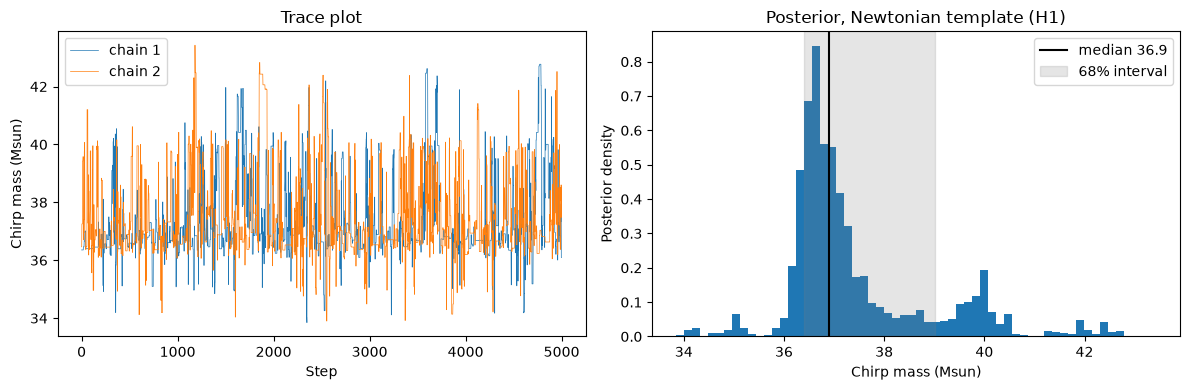

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for k, c in enumerate(mc_chains):
    ax[0].plot(c, lw=0.5, label=f'chain {k + 1}')
ax[0].set_xlabel('Step')
ax[0].set_ylabel('Chirp mass (Msun)')
ax[0].set_title('Trace plot')
ax[0].legend()

ax[1].hist(mc_all, bins=60, density=True)
ax[1].axvline(med, color='k', label=f'median {med:.1f}')
ax[1].axvspan(lo, hi, alpha=0.2, color='grey', label='68% interval')
ax[1].set_xlabel('Chirp mass (Msun)')
ax[1].set_ylabel('Posterior density')
ax[1].set_title('Posterior, Newtonian template (H1)')
ax[1].legend()
plt.tight_layout()
plt.savefig('figures/posterior_mc.png', dpi=150)
plt.show()

Q: Load waveform:

In [35]:
WAVEFORM_FILE = r'C:\Users\stels\Downloads\gw150914_like_imrphenomd.npz'
print('Waveform file found?', os.path.exists(WAVEFORM_FILE))     # should print True

wf = np.load(WAVEFORM_FILE)
h_wf, i_peak, MC_TRUE = wf['h'], int(wf['i_peak']), float(wf['mc_true'])

def load_noise_segment(event, detector, duration, offset):
    """`duration` s of real detector noise from the bulk file, centred `offset` s from the event."""
    t_centre = float(np.load(f'{detector}_{event}_{duration}s.npz')['t0']) + offset
    with h5py.File(f'{detector}_{event}_bulk.hdf5', 'r') as f:
        dset = f['strain/Strain']
        dt = dset.attrs['Xspacing']
        t_start = f['meta/GPSstart'][()]
        i_c = int(round((t_centre - t_start) / dt))
        half = int(round(duration / 2 / dt))
        return dset[i_c - half : i_c + half]

noise_seg = load_noise_segment(EVENT, DETECTOR, DURATION, offset=-300)
print(len(noise_seg), 'samples, any missing values?', np.isnan(noise_seg).any())

Waveform file found? True
131072 samples, any missing values? False


R: Reusable likelihood builder:

In [36]:
def build_log_likelihood(strain_seg, f_max=F_MAX):
    """Return a log-likelihood function for this stretch of data (PSD estimated from it)."""
    seg_hp = highpass(strain_seg, fs)
    seg_psd = estimate_psd(seg_hp, fs)
    b = (freqs >= F_LOW) & (freqs <= f_max)
    nrm = np.sqrt(seg_psd[b] * fs / 2) * np.sqrt(len(times) * np.mean(window**2) / 2)

    def wfft(x):
        return np.fft.rfft(x * window)[b] / nrm

    d = wfft(seg_hp)
    yy = np.concatenate([d.real, d.imag])

    def log_like(mc, tc):
        h_cos, h_sin = chirp_template(times, mc, tc, f_max=f_max)
        c, s = wfft(h_cos), wfft(h_sin)
        A = np.column_stack([np.concatenate([c.real, c.imag]),
                             np.concatenate([s.real, s.imag])])
        coef, *_ = np.linalg.lstsq(A, yy, rcond=None)
        r = yy - A @ coef
        return -0.5 * r @ r

    return log_like

def optimal_snr(h, noise_psd, f_lo=F_LOW, f_hi=F_HIGH):
    """SNR a perfect template would get for signal h in noise with this PSD."""
    b = (freqs >= f_lo) & (freqs <= f_hi)
    nrm = np.sqrt(noise_psd[b] * fs / 2) * np.sqrt(len(times) * np.mean(window**2) / 2)
    hw = np.fft.rfft(h * window)[b] / nrm
    return np.sqrt(np.sum(np.abs(hw)**2))

S: inject signal

In [37]:
TARGET_SNR = 20                                  # GW150914's SNR in Hanford
signal = np.zeros(len(times))
i0 = np.argmin(np.abs(times)) - i_peak           # put the waveform's peak at t = 0
signal[i0:i0 + len(h_wf)] = h_wf

noise_psd = estimate_psd(highpass(noise_seg, fs), fs)
signal *= TARGET_SNR / optimal_snr(signal, noise_psd)
injected = noise_seg + signal
print('Injected SNR:', round(optimal_snr(signal, noise_psd), 1), '  true Mc:', round(MC_TRUE, 2), 'Msun')

Injected SNR: 20.0   true Mc: 30.72 Msun


T: Run MCMC on injected signal

In [38]:
def make_log_posterior(log_like, tc_centre, half_width=0.02):
    """Same priors as Cell M, for any likelihood."""
    def log_post(theta):
        ln_mc, tc = theta
        mc = np.exp(ln_mc)
        if not (MC_MIN < mc < MC_MAX and abs(tc - tc_centre) < half_width):
            return -np.inf
        return ln_mc + log_like(mc, tc)
    return log_post

def best_tc(log_like, mc, centre, half_width=0.02):
    """Grid search for the best tc at fixed Mc (used for starting points)."""
    tcs = np.arange(centre - half_width, centre + half_width, 0.0005)
    return tcs[np.argmax([log_like(mc, t) for t in tcs])]

def run_chains(log_like, tc_centre, n_steps=5000, seed=42, start_mcs=(32, 42)):
    """Tune and run one chain per starting Mc; return all Mc samples combined."""
    rng = np.random.default_rng(seed)
    log_post = make_log_posterior(log_like, tc_centre)
    chains = []
    for k, mc0 in enumerate(start_mcs):
        start = (np.log(mc0), best_tc(log_like, mc0, tc_centre))
        print(f'Chain {k + 1}, starting at Mc = {mc0}')
        x, cov = tune(log_post, start, rng)
        chain, _, acc = metropolis(log_post, x, cov, n_steps, rng)
        print(f'  main run: acceptance {acc:.2f}')
        chains.append(chain)
    mc_chains = [np.exp(c[:, 0]) for c in chains]
    print('R-hat (Mc):', round(gelman_rubin(mc_chains), 3))
    return np.concatenate(mc_chains)

log_like_inj = build_log_likelihood(injected)
tc_inj = best_tc(log_like_inj, 37, centre=0.0)
mc_inj = run_chains(log_like_inj, tc_inj)

lo, med, hi = np.percentile(mc_inj, [16, 50, 84])
print(f'Recovered: {med:.1f} +{hi - med:.1f} / -{med - lo:.1f} Msun   (true {MC_TRUE:.2f})')
print(f'Bias: {med - MC_TRUE:+.1f} Msun ({(med / MC_TRUE - 1) * 100:+.0f}%)')

Chain 1, starting at Mc = 32
  pilot round 0: acceptance 0.60
  pilot round 1: acceptance 0.17
  pilot round 2: acceptance 0.21
  main run: acceptance 0.22
Chain 2, starting at Mc = 42
  pilot round 0: acceptance 0.55
  pilot round 1: acceptance 0.38
  pilot round 2: acceptance 0.25
  main run: acceptance 0.17
R-hat (Mc): 1.005
Recovered: 38.3 +1.3 / -2.1 Msun   (true 30.72)
Bias: +7.5 Msun (+25%)


U: Figure for comparisson

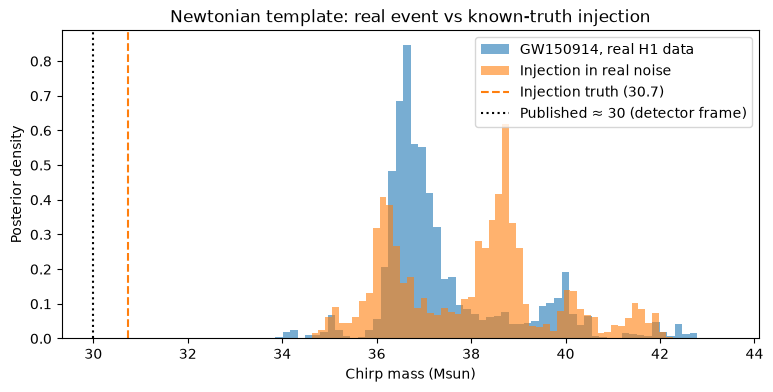

In [39]:
plt.figure(figsize=(9, 4))
plt.hist(mc_all, bins=60, density=True, alpha=0.6, label='GW150914, real H1 data')
plt.hist(mc_inj, bins=60, density=True, alpha=0.6, label='Injection in real noise')
plt.axvline(MC_TRUE, color='C1', ls='--', label=f'Injection truth ({MC_TRUE:.1f})')
plt.axvline(30, color='k', ls=':', label='Published ≈ 30 (detector frame)')
plt.xlabel('Chirp mass (Msun)')
plt.ylabel('Posterior density')
plt.title('Newtonian template: real event vs known-truth injection')
plt.legend()
plt.savefig('figures/injection_vs_real.png', dpi=150)
plt.show()

V: Sensitivity and template cut-off

In [40]:
sensitivity = {150: np.percentile(mc_all, [16, 50, 84])}   # the main result, from Cell O

for f_max in (120, 180):
    print(f'\n=== F_MAX = {f_max} Hz ===')
    ll = build_log_likelihood(strain, f_max=f_max)
    tc0 = best_tc(ll, 37, centre=tc_peak)
    samples = run_chains(ll, tc0, n_steps=3000)
    sensitivity[f_max] = np.percentile(samples, [16, 50, 84])

print('\nF_MAX (Hz) | chirp mass (Msun)')
for f_max in sorted(sensitivity):
    lo, med, hi = sensitivity[f_max]
    print(f'   {f_max:4d}    | {med:5.1f} +{hi - med:.1f} / -{med - lo:.1f}')


=== F_MAX = 120 Hz ===
Chain 1, starting at Mc = 32
  pilot round 0: acceptance 0.62
  pilot round 1: acceptance 0.33
  pilot round 2: acceptance 0.17
  main run: acceptance 0.22
Chain 2, starting at Mc = 42
  pilot round 0: acceptance 0.61
  pilot round 1: acceptance 0.27
  pilot round 2: acceptance 0.26
  main run: acceptance 0.28
R-hat (Mc): 1.001

=== F_MAX = 180 Hz ===
Chain 1, starting at Mc = 32
  pilot round 0: acceptance 0.45
  pilot round 1: acceptance 0.32
  pilot round 2: acceptance 0.34
  main run: acceptance 0.31
Chain 2, starting at Mc = 42
  pilot round 0: acceptance 0.45
  pilot round 1: acceptance 0.29
  pilot round 2: acceptance 0.28
  main run: acceptance 0.31
R-hat (Mc): 1.003

F_MAX (Hz) | chirp mass (Msun)
    120    |  37.7 +0.5 / -0.6
    150    |  36.9 +2.1 / -0.5
    180    |  37.1 +0.3 / -0.3
